# Interpolation tool

This is a QC (Quality Control) driven data interpolation tool for UK-Flow-15 time-series flow data.  

The code reads CSV files containing sensor readings every 15 minutes, finds data points flagged as poor quality, replaces them with interpolated values, and saves the cleaned data.

### Quality Control Flags
Each timestep in the flow data is assigned a three-digit QC code as part of the quality control procedure. Each digit of the three-digit code (X,Y,Z) represents the result of an independent check:
 
- (X): Consistency check against other established UK hydrological products 
- (Y): Standard QC anomaly checks 
- (Z): High-flow event checks 

![QC Code](InputFigures/QC_Code.png)

For each of the three checks, the digit value indicates the severity of the issue — for example, a 0 might mean the data passed cleanly, while higher digits indicate progressively worse problems. 

The tables below list the meaning of the range of possible values for each of the three checks. So, for a value of 204, this means that for 1974-12-28 15:45:00:
 
- (X): 2 -> Mismatch >20% between 15-min values and POT values (Consistency check against other established UK hydrological products)
- (Y): 0 -> No issues found (Standard QC anomaly checks)
- (Z): 4 -> Event with >0.1 annual likelihood and no concurrent high flow in the hydrometric area (High-flow event checks) 

<img src="InputFigures/QC_Table1.png" width="400" height="200">
<img src="InputFigures/QC_Table2.png" width="400" height="200">
<img src="InputFigures/QC_Table3-2.png" width="400" height="200">
<img src="InputFigures/QC_Table3-1.png" width="400" height="200"> 

<!-- ### Filtering by QC Flag

The presence of these QC flags allows users to identify 'bad' data points in the timeseries, and to replace their values using time-based interpolation from the surrounding 'good' data. 

To filter out bad data, two things must be specified:  

- qc_column — which column to look at (0=X, 1=Y, 2=Z)
- qc_flags — which digit values in that position should be treated as bad data

For example, qc_column=1, qc_flags="38" would flag any timestep where the Y check returned a 3 or an 8:

"137" → Y digit is 3 → flagged ✗  
"060" → Y digit is 6 → not flagged ✓  
"238" → Y digit is 3 → flagged ✗  

Flagged values are then replaced by time-based interpolation from the surrounding good data. -->

## Read in and clean the flow data

In [18]:
### Initial setup variables
import os
import pandas as pd
import sys
import numpy as np
sys.path.insert(1, '../')
from functions import *
import matplotlib.pyplot as plt

In [19]:
station_id = '042006' # '042006' #'026017'

### Data Format:
Each station has a CSV file with these columns:

- Datetime — timestamp (used as the index)  
- Value — the flow measurement at the station in m3s-1
- Resolution - the original temporal interval between each observation in minutes. Regular intervals are indicated numerically, for instance, 120 representing a two-hour interval. Special cases include irregular time intervals, which are coded as 0, and intervals with an anomalous one-second gap, coded as 1   
- Flag — a quality control code, e.g. 060 or 137 

In [20]:
def load_station_data(station_id: str) -> pd.DataFrame:
    url = f"https://catalogue.ceh.ac.uk/datastore/eidchub/211710ac-f01b-4b52-807f-373babb1c368/1_RiverFlowStations/{station_id}.csv"
    return pd.read_csv(url, parse_dates=["datetime"], index_col="datetime")
df = load_station_data(station_id)
df.head()

,value,resolution,flag
datetime,,,
1981-08-01 00:00:00,0.623,NaN,0.0
1981-08-01 00:15:00,0.628,15.0,0.0
1981-08-01 00:30:00,0.633,15.0,0.0
1981-08-01 00:45:00,0.637,15.0,0.0
1981-08-01 01:00:00,0.642,15.0,0.0


### Clean data

In [21]:
# Clean rows where value is string 'NA' (but keep numeric instances of NAN)
df = remove_empty(df)
# Ensure values are numeric
df["value"] = pd.to_numeric(df["value"], errors="coerce")

# =============================================================================
# Standardise QC flags
# =============================================================================
# QC flags are stored as numbers (e.g. 60, 7, 137) but we need to inspect
# individual digits by position. To do this reliably, we first convert all
# flags to zero-padded 3-character strings so that every flag has exactly
# three digits and the X, Y, Z positions are always consistent.
#
#   7   ->  "007"   (X=0, Y=0, Z=7)
#   60  ->  "060"   (X=0, Y=6, Z=0)
#   137 ->  "137"   (X=1, Y=3, Z=7)

flag_padded = normalize_flag_to_3char(df["flag"])

# Store the padded flags in the dataframe so they are visible when inspecting the data
df["flag_padded"] = flag_padded

### Explore the presence of QC flags

This figures plots the number of timesteps which are flagged with each of the values.

NB: WOULD BE GOOD TO HASH OUT THE VALUES THAT ARENT POSSIBLE FOR 0 (X)

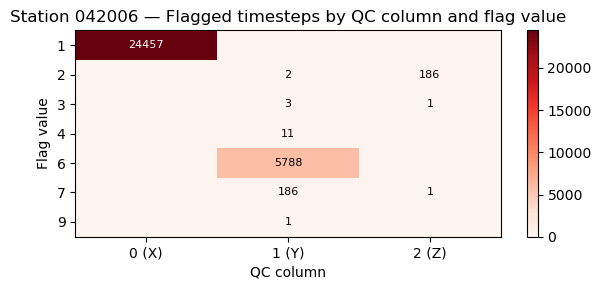

In [22]:
# Explore all columns and all flag values
summary = explore_qc_flags(df, station_id, print_summary_table=False)

# Or focus on specific columns and flags of interest
# summary = explore_qc_flags(df, station_id, qc_columns=[1, 2], qc_flags=["2", "3", "7", "8"])

In [ ]:
# All three columns
plot_qc_flag_distribution(df, station_id)

# Or focus on specific columns
# plot_qc_flag_distribution(df, station_id, qc_columns=[0, 1])

###  Identify problematic time steps

In [ ]:
# qc_column = 2
# qc_flags = '238'

qc_column = 1
qc_flags = '6'
round_decimals =1

### Selecting QC flags for interpolation

Based on the exploration above, we select:

- **`qc_column = 1`** (Y — Standard QC anomaly checks)
- **`qc_flags = '238'`** (flag values indicating anomalous readings)

These were chosen because the heatmap shows the majority of flagged timesteps 
occur in the Y column with these values, and the distribution plot confirms they 
are isolated events rather than systematic gaps.

In [ ]:
# =============================================================================
# STEP 2: IDENTIFY FLAGGED (BAD) ROWS
# =============================================================================
# Using the padded flags, we now identify which rows should be interpolated.
# This is controlled by two parameters:
#
#   qc_column : which digit position to inspect (0=X, 1=Y, 2=Z)
#   qc_flags  : which digit values at that position indicate bad data
#
# For example, qc_column=1 and qc_flags="38" would flag any row where
# the Y digit is a 3 or an 8.
#
# The result is a boolean Series (True/False for every row) indicating
# which rows are flagged for interpolation.

flagged_rows = build_qc_mask(flag_padded, qc_column=qc_column, qc_flags=qc_flags)

# Preview which rows have been flagged
print(f"\n{flagged_rows.sum()} rows flagged for interpolation out of {len(df)} total rows.")
# df.loc[flagged_rows, ["flag", "flag_padded", "value"]][:40]

# Find contiguous clusters of flagged rows
flagged_positions = np.where(flagged_rows)[0]
clusters = np.split(flagged_positions, np.where(np.diff(flagged_positions) > 1)[0] + 1)

if len(clusters) < 0 :
    plot_flagged_clusters(df, clusters, station_id)

In [ ]:
# =============================================================================
# STEP 3: RECORD THE ORIGINAL VALUES BEFORE INTERPOLATION
# =============================================================================
# Before we overwrite any values, we save the original values of the flagged
# rows. This gives us a log of what changed, which is useful for auditing
# and quality checking the interpolation afterwards.

old_values = ( df.loc[flagged_rows, ["value"]]   # extract only the flagged rows
    .rename(columns={"value": "old_value"})  # rename so it is clear these are the originals
    .reset_index())                # move datetime from index to a regular column

In [ ]:
# =============================================================================
# VISUALISATION 3: FLAGGED TIMESTAMPS ALONG THE TIME AXIS
# =============================================================================
# This plot shows when flagged points occur across the full record.
# Each flagged timestamp is marked as a vertical line, making it easy to
# see whether bad data is clustered in time (e.g. during a particular season
# or instrument failure period) or scattered randomly throughout the record.
# This is useful context for judging how reliable the interpolation is likely
# to be — clustered gaps are harder to interpolate accurately than isolated points.

fig, ax = plt.subplots(figsize=(14, 2))

ax.vlines( pd.to_datetime(old_values["datetime"]), ymin=0, ymax=1,color="red", linewidth=0.5, alpha=0.7)

# Add a shaded background to represent the full record extent
ax.axhspan(0, 1, color="lightgrey", alpha=0.3)

ax.set_title(f"Station {station_id} — Distribution of flagged timestamps across the full record")
ax.set_xlabel("Datetime")
ax.set_yticks([])  # y axis is not meaningful here
plt.tight_layout()
plt.show()

In [ ]:
# =============================================================================
# STEP 4: PREPARE THE DATA FOR INTERPOLATION
# =============================================================================
# Time-based interpolation requires the data to be sorted chronologically
# and for each timestamp to appear only once. If duplicate timestamps exist,
# we collapse them by taking the mean, since interpolation cannot handle
# multiple values at the same point in time.

df = df.sort_index()

if not df.index.is_unique:
    print("\nDuplicate timestamps found — collapsing by taking the mean value at each timestamp.")
    df = df.groupby(level=0).mean(numeric_only=True)

# =============================================================================
# STEP 5: REPLACE FLAGGED VALUES WITH INTERPOLATED ESTIMATES
# =============================================================================
# We set the flagged values to NaN (null), then use time-based linear
# interpolation to estimate replacement values. Unlike simple positional
# interpolation, time-based interpolation accounts for uneven gaps between
# timestamps — so a 6-hour gap is treated differently to a 1-hour gap.

df.loc[flagged_rows, "value"] = pd.NA

df["value"] = df["value"].interpolate(method="time")

# Optionally round the interpolated values to a specified number of decimal places
if (round_decimals is not None) and (round_decimals >= 0):
    df["value"] = df["value"].round(round_decimals)

# =============================================================================
# STEP 6: BUILD THE INTERPOLATION LOG
# =============================================================================
# Finally, we combine the original values (saved in Step 3) with the new
# interpolated values to produce a log of every change made. This log can
# be saved to a CSV for auditing purposes.

old_values["new_value"] = old_values["datetime"].map(df["value"])
old_values["station"] = station_id

interp_log = old_values[["station", "datetime", "old_value", "new_value"]]

print("\nInterpolation log (old vs new values):")
print(interp_log.head(10))

In [ ]:
# =============================================================================
# CHECK: IDENTIFY POINTS THAT COULD NOT BE INTERPOLATED
# =============================================================================
# Time-based interpolation cannot fill values at the edges of the record
# where there is no preceding or following real value to interpolate from.
# These will remain as NaN in the cleaned data.

unresolved = interp_log[interp_log["new_value"].isna()]
if not unresolved.empty:
    print(f"Warning: {len(unresolved)} point(s) could not be interpolated "
          f"(no surrounding data available):")
    print(unresolved[["datetime", "old_value"]].to_string(index=False))
else:
    print("All flagged points were successfully interpolated.")

In [ ]:
# # =============================================================================
# # VISUALISATION 2: ZOOMED VIEW AROUND EACH FLAGGED POINT
# # =============================================================================
# # For each flagged timestep, this plots a small window of 10 timesteps
# # either side, showing the original uncleaned time series (blue), with the
# # flagged value highlighted in red. The interpolated replacement is shown
# # as a green cross for reference.

# timestep_idx = 2
# row = old_values.iloc[timestep_idx]

# # Find the integer position of this flagged timestep in the dataframe
# pos = df.index.get_loc(row["datetime"])

# # Define the window as 10 timesteps either side, clamped to the dataframe bounds
# window_start = max(0, pos - 10)
# window_end = min(len(df) - 1, pos + 10)

# # Subset the ORIGINAL data to the window (before interpolation)
# # We reconstruct the original by replacing the interpolated value
# # with the old value at the flagged timestep
# df_window = df.iloc[window_start:window_end + 1].copy()
# df_window.loc[row["datetime"], "value"] = row["old_value"]

# fig, ax = plt.subplots(figsize=(10, 4))

# # Plot the original time series (with the flagged value still in place)
# ax.plot(df_window.index, df_window["value"],
#         color="black", linewidth=0.8)
# ax.scatter(df_window.index, df_window["value"],
#         color="black", linewidth=0.8, label="Original time series")

# # Highlight the flagged point in red
# ax.scatter(row["datetime"], row["old_value"],
#            color="red", zorder=5, s=60, label=f"Flagged value: {row['old_value']:.1f}")

# # Show the interpolated replacement as a reference
# ax.scatter(row["datetime"], row["new_value"],
#            color="green", zorder=5, s=60, marker="x", label=f"Interpolated replacement: {row['new_value']:.1f}")

# ax.set_title(f"Station {station_id} — Flagged point at {row['datetime']} (±10 timesteps)")
# ax.set_xlabel("Datetime")
# ax.set_ylabel("Flow value")
# ax.legend()

# fig.tight_layout()


In [ ]:
# # Show original flagged values
# plot_flagged_clusters(df, clusters, interp_log, station_id)

# # Show with interpolated values overlaid
# plot_flagged_clusters(df, clusters, interp_log, station_id, show_interpolated=True)

# Adjust context window size
plot_flagged_clusters(df, clusters, station_id, interp_log, show_interpolated=False, n_context=10)

In [ ]:
# # =============================================================================
# # VISUALISATION: FULL TIME SERIES WITH FLAGGED POINTS + DISTRIBUTION
# # =============================================================================
# # Two-panel plot: the top panel shows the full time series with flagged points
# # highlighted in red, and the bottom panel shows when those points occur across
# # the record — making it easy to see both the values and their timing at once.

# fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6),
#                                 gridspec_kw={"height_ratios": [4, 1]},
#                                 sharex=True)

# # --- Top panel: full time series ---
# ax1.plot(df.index, df["value"], color="black", linewidth=0.8)
# ax1.scatter(df.loc[flagged_rows].index, df.loc[flagged_rows, "value"],
#             color="red", zorder=5, s=20, label="Flagged values")
# ax1.set_ylabel("Flow value")
# ax1.legend()
# ax1.set_title(f"Station {station_id} — Full time series with flagged points")

# # --- Bottom panel: distribution of flagged timestamps ---
# ax2.axhspan(0, 1, color="lightgrey", alpha=0.3)
# ax2.vlines(
#     df.loc[flagged_rows].index,
#     ymin=0, ymax=1,
#     color="red", linewidth=0.5, alpha=0.7
# )
# ax2.set_yticks([])
# ax2.set_xlabel("Datetime")

# fig.tight_layout()
# plt.show()